# Solution for Exercise 02 - Euler's Equation
---

<!--NAVIGATION-->
< previous: [S01 Function Generator](./S01-Function-Generator.ipynb) | [Exercise 02](./E02-Eulers-Equation.ipynb) | [Contents / Overview Notebook]((./00-Python-Notebooks-Overview-EN.ipynb)) | next: [S03](S02-Eulers-Equation.ipynb) >
    
---

<a id='task_function_generator'></a>
<div class="alert alert-block alert-success">
<strong>Intended Learning Objectives (ILOs)</strong><br>
    
After completing this Jupyter Notenook you should be able to:
    
<ul>
<li>To introduce Euler's Formula as an alternative way of representing trigonometric functions, which will later present a convenient format for signal manipulation
</li>
<li>understand basic use of functions from the <code>Python</code> libraries 
<ul>
<li><a href="https://matplotlib.org/"><code>Matplotlib</code></a> for graphical output (like <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html"><code>plot()</code></a>, <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplot.html"><code>subplot()</code></a>, etc.)
</li>
<li><code>Numpy</code> for basic mathematical functions like <code>exp()</code>, <code>real()</code>, <code>imag()</code>, etc.
</li> 
</ul>
</ul>
</div>

## Background Theory

Sometimes it can be useful in signal processing to describe trigonometric functions in different ways. Euler's Formula expresses the relationship between the exponential function and the trigonometric functions.

$$ e^{j\phi k} = (\cos(\phi k) + j\sin(\phi k))$$

or

$$ \cos(\phi k) = \frac{1}{2}(e^{j\phi k} + e^{-j\phi k})$$
$$ \sin(\phi k) = \frac{1}{2j}(e^{j\phi k} - e^{-j\phi k})$$

For more information on the imaginary number $j$, exponential functions and Euler's formula, see the provided notebooks. For now, we can demonstrate the connection below.

<a id='task2a'></a>
<div class="alert alert-block alert-info">
<strong>Task 2 (a): Sine signal</strong><br>
<ul>
<li>Plot a sine wave from $0$ to $6\pi$ with $32$ samples per period.
</li>
</ul>
</div>

In [2]:
# Let's do some necessary and nice-to-have imports
%matplotlib inline
import matplotlib.pyplot as plt  # plotting
#import seaborn as sns; sns.set() # styling
import numpy as np               # math
import IPython.display as ipd    # for audio playback

One period of a sine wave is $2 \pi$. Therefore an easy way to solve Task 2 (a) is simply to create a sine wave with a freqyency of $f_0=1$ and set the sampling frequency to $f_s=32$. Since $\frac{3 \cdot 2 \pi}{2\pi} = \frac{6\pi}{2\pi} = 3$ periods, we'll need $f_s \cdot 3 = 96$ samples.

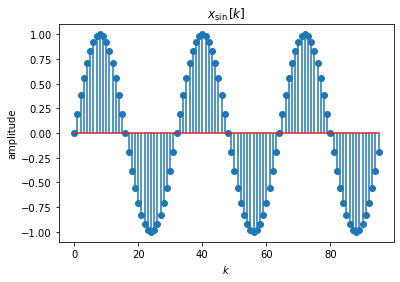

In [5]:
f0 = 1                          # frequency
fs = 32                         # sampling rate
k = np.arange(fs*3)             # time index
Omega0 = 2 * np.pi * f0 / fs      # normalised angular frequency
sin_x = np.sin(Omega0 * k)        # sine signal

plt.figure()
plt.title('$x_{\sin}[k]$')
plt.xlabel("$k$")
plt.ylabel("amplitude")
plt.stem(sin_x,use_line_collection = True);

<a id='task2b'></a>
<div class="alert alert-block alert-info">
<strong>Task 2 (b)</strong><br>
<ul>
<li> Represent the corresponding complex exponential sequence in the complex plane (i.e. imaginary part on the $y$-axis, real part on the $x$-axis) and as a real part, imaginary part and absolute value depending on the time index $k$.
</li>
</ul>
</div>

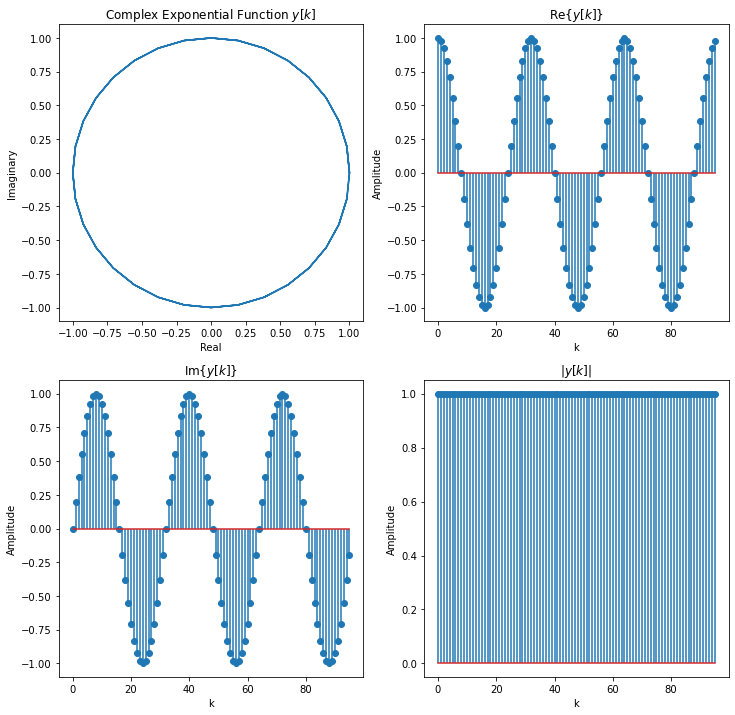

In [7]:
f0 = 1                        # frequency
fs = 32                       # sampling rate 
k = np.arange(fs*3)           # time index
Omega0 = 2 * np.pi * f0 / fs    # normalised angular frequency
exp = np.exp(1j * Omega0 * k)   # exponential sequence
real = exp.real               # real component
imag = exp.imag               # imagainary component
abs = np.abs(exp)             # absolute value

plt.figure(figsize=(12,12))
plt.subplot(2,2,1)
plt.title('Complex Exponential Function $y[k]$')
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.plot(real,imag)

plt.subplot(2,2,2)
plt.title('Re$\{y[k]\}$')
plt.xlabel("k")
plt.ylabel("Amplitude")
plt.stem(real, use_line_collection = True)

plt.subplot(2,2,3)
plt.title('Im$\{y[k]\}$')
plt.xlabel("k")
plt.ylabel("Amplitude")
plt.stem(imag, use_line_collection = True)

plt.subplot(2,2,4)
plt.title('$|y[k]|$')
plt.xlabel("k")
plt.ylabel("Amplitude")
plt.stem(abs, use_line_collection = True);

<a id='task2c'></a>
<div class="alert alert-block alert-info">
<strong>Task 2 (c)</strong><br>

Use Euler's Formula to generate a sine sequence using the complex exponential sequences and compare this with the sine sequence from <a href="#task2a">Task 2 (a)</a>.
</div>

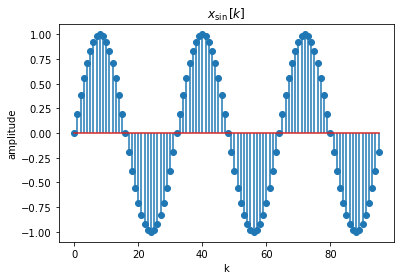

In [10]:
f0 = 1                        # frequency
fs = 32                       # sampling rate 
k = np.arange(fs*3)           # time index
Omega0 = 2 * np.pi * f0 / fs  # normalised angular frequency
sin_x = 1 / 2j * (np.exp(1j * Omega0 * k)-np.exp(-1j * Omega0 * k)) # Euler's formula for sine

plt.figure()
plt.title('$x_{\sin}[k]$')
plt.xlabel("k")
plt.ylabel("amplitude")
plt.stem(sin_x.real,use_line_collection = True);

> As expected, the graph is identical to Task a).